# 03 - Tính Toán Số Học Từng Bước Thuật Toán AdaBoost (Toy Dataset)

**Môn học:** Nhập môn Học máy (Introduction to Machine Learning)  
**Tiểu luận Giữa kỳ:** Ensemble Learning (Phương pháp Boosting - Thuật toán AdaBoost)  
**Phụ trách:** Nguyễn Anh Hào (MSSV: 52400186) - Gói B  

---

## 📌 Mục tiêu của Notebook
1. **Kiểm chứng số học 100% bằng tay & đối soát bằng mã nguồn:** Trình bày chi tiết từng bước thuật toán AdaBoost qua 3 vòng lặp ($t = 1, 2, 3$) với bộ phân loại cơ sở là cây quyết định 1 tầng (**Decision Stumps**).
2. **Minh họa cơ chế thích nghi (Adaptive Sample Weighting):** Chứng minh công thức cập nhật trọng số mẫu $w_i$, tính toán sai số có trọng số $\epsilon_t$, trọng số mô hình $\alpha_t$, và hệ số chuẩn hóa $Z_t$.
3. **Trực quan hóa sinh động:** Vẽ phân phối các mẫu dữ liệu với kích thước điểm (marker size) tỉ lệ thuận với trọng số mẫu $w_i$, giúp quan sát rõ cách thuật toán "phạt" các mẫu dự đoán sai và "thưởng" các mẫu dự đoán đúng.
4. **Hội tụ 100%:** Chứng minh cơ chế biểu quyết có trọng số (Weighted Voting) giúp tổ hợp 3 mô hình yếu đạt độ chính xác tuyệt đối $100\%$ ($8/8$ mẫu).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.precision", 4)

## 1. Khởi tạo Toy Dataset (8 mẫu) & Trọng số ban đầu

Tập dữ liệu một chiều (1D) gồm $N = 8$ mẫu lâm sàng:
* Đặc trưng $X \in \{1, 2, 3, 4, 5, 6, 7, 8\}$.
* Nhãn phân loại $y \in \{-1, +1\}$ (+1: Nguy cơ cao, -1: Nguy cơ thấp).
* Ban đầu, mọi mẫu đều có vai trò như nhau: $w_i^{(1)} = \frac{1}{N} = \frac{1}{8} = 0.1250$.

In [2]:
X = np.array([1, 2, 3, 4, 5, 6, 7, 8])
y = np.array([-1, -1, 1, 1, 1, -1, -1, 1])
N = len(y)
w1 = np.ones(N) / N

df_init = pd.DataFrame({
    "Mẫu (i)": np.arange(1, N + 1),
    "Đặc trưng X": X,
    "Nhãn thực tế y": y,
    "Trọng số ban đầu w^(1)": w1
})
df_init

Mẫu (i),Đặc trưng X,Nhãn thực tế y,Trọng số ban đầu w^(1)
1,1,-1,0.125
2,2,-1,0.125
3,3,1,0.125
4,4,1,0.125
5,5,1,0.125
6,6,-1,0.125
7,7,-1,0.125
8,8,1,0.125


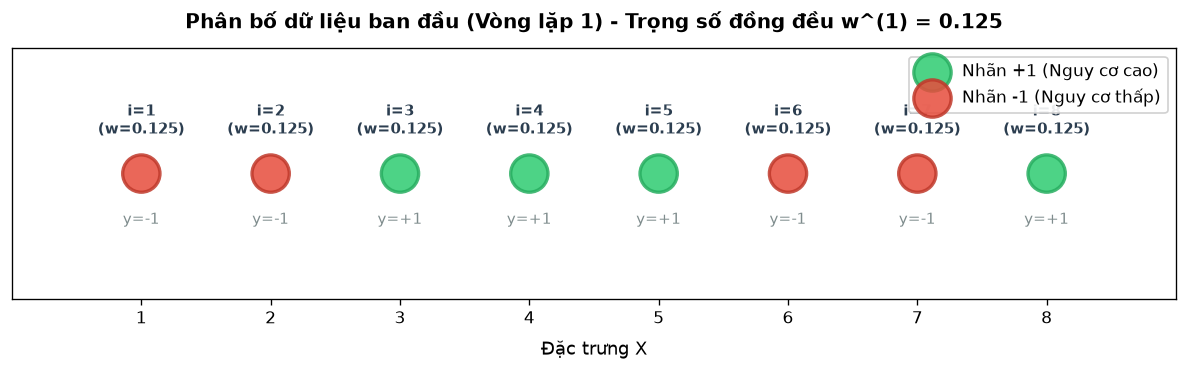

In [3]:
def plot_samples(X, y, weights, title, stump_threshold=None, stump_title=None):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    sizes = weights * 4000
    pos_mask = (y == 1)
    neg_mask = (y == -1)
    
    ax.scatter(X[pos_mask], np.zeros(np.sum(pos_mask)), s=sizes[pos_mask], 
               color="#2ecc71", edgecolor="#27ae60", linewidth=2, label="Nhãn +1 (Nguy cơ cao)", alpha=0.85, zorder=3)
    ax.scatter(X[neg_mask], np.zeros(np.sum(neg_mask)), s=sizes[neg_mask], 
               color="#e74c3c", edgecolor="#c0392b", linewidth=2, label="Nhãn -1 (Nguy cơ thấp)", alpha=0.85, zorder=3)
    
    for i in range(len(X)):
        ax.annotate(f"i={i+1}\n(w={weights[i]:.3f})", (X[i], 0.08), 
                    ha="center", fontsize=9, fontweight="bold", color="#2c3e50")
        ax.annotate(f"y={'+1' if y[i]==1 else '-1'}", (X[i], -0.1), 
                    ha="center", fontsize=9, color="#7f8c8d")
    
    if stump_threshold is not None:
        ax.axvline(x=stump_threshold, color="#3498db", linestyle="--", linewidth=2.5, 
                   label=f"Ranh giới Stump: x = {stump_threshold}", zorder=2)
        if stump_title:
            ax.set_title(f"{title}\n{stump_title}", fontsize=11, fontweight="bold", pad=12)
    else:
        ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
        
    ax.set_xlim(0, 9)
    ax.set_ylim(-0.25, 0.25)
    ax.set_xticks(range(1, 9))
    ax.set_xlabel("Đặc trưng X", fontsize=11, labelpad=8)
    ax.get_yaxis().set_visible(False)
    ax.legend(loc="upper right", frameon=True, framealpha=0.9)
    plt.tight_layout()
    plt.show()

plot_samples(X, y, w1, "Phân bố dữ liệu ban đầu (Vòng lặp 1) - Trọng số đồng đều w^(1) = 0.125")

## 2. VÒNG LẶP 1 ($t = 1$)
### 2.1. Chọn mô hình yếu (Decision Stump 1)
Quy tắc Stump 1:
$$h_1(x) = \begin{cases} +1 & \text{nếu } x > 2.5 \\ -1 & \text{nếu } x \le 2.5 \end{cases}$$

### 2.2. Tính toán các chỉ số:
1. **Dự đoán của $h_1(x)$:**
   * $X \le 2.5$ ($X \in \{1, 2\}$) $\to$ dự đoán $-1$ (ĐÚNG với nhãn thực tế).
   * $X > 2.5$ ($X \in \{3, 4, 5, 6, 7, 8\}$) $\to$ dự đoán $+1$.
   * Trong đó mẫu 6 và 7 có nhãn thực tế là $-1$ nhưng bị dự đoán là $+1$ $\implies$ **Mẫu 6 và 7 bị sai**.
2. **Sai số phân loại có trọng số $\epsilon_1$:**
   $$\epsilon_1 = \sum_{i: h_1(x_i) \neq y_i} w_i^{(1)} = w_6^{(1)} + w_7^{(1)} = \frac{1}{8} + \frac{1}{8} = \frac{1}{4} = 0.2500$$
3. **Trọng số tin cậy của mô hình $\alpha_1$:**
   $$\alpha_1 = \frac{1}{2} \ln \left( \frac{1 - \epsilon_1}{\epsilon_1} \right) = \frac{1}{2} \ln(3) \approx 0.5493$$
4. **Hệ số chuẩn hóa $Z_1$ và Cập nhật trọng số mẫu:**
   * $Z_1 = 2 \sqrt{\epsilon_1(1 - \epsilon_1)} = 2 \sqrt{0.25 \times 0.75} = \frac{\sqrt{3}}{2} \approx 0.8660$
   * Mẫu đúng: $w_i^{(2)} = \frac{1/8 \times \exp(-0.5493)}{\sqrt{3}/2} = \frac{1}{12} \approx 0.0833$
   * Mẫu sai (6, 7): $w_i^{(2)} = \frac{1/8 \times \exp(+0.5493)}{\sqrt{3}/2} = \frac{1}{4} = 0.2500$

-> Sai số e1: 0.2500 (Chính xác = 1/4)
-> Trọng số alpha1: 0.5493 (Chính xác = 0.5 * ln(3))
-> Hệ số chuẩn hóa Z1: 0.8660 (Chính xác = sqrt(3)/2)
-> Trọng số mẫu sai (6, 7) tăng lên: 0.2500
-> Trọng số mẫu đúng giảm xuống: 0.0833


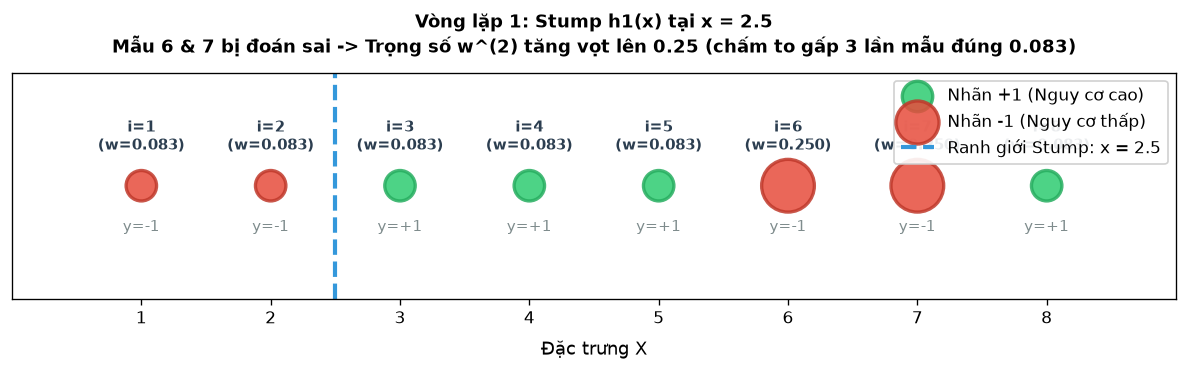

In [4]:
# Stump 1
h1 = np.where(X > 2.5, 1, -1)
misc1 = (h1 != y)
err1 = np.sum(w1[misc1])
alpha1 = 0.5 * np.log((1 - err1) / err1)
w2_unnorm = w1 * np.exp(-alpha1 * y * h1)
Z1 = np.sum(w2_unnorm)
w2 = w2_unnorm / Z1

print(f"-> Sai số e1: {err1:.4f} (Chính xác = 1/4)")
print(f"-> Trọng số alpha1: {alpha1:.4f} (Chính xác = 0.5 * ln(3))")
print(f"-> Hệ số chuẩn hóa Z1: {Z1:.4f} (Chính xác = sqrt(3)/2)")
print(f"-> Trọng số mẫu sai (6, 7) tăng lên: {w2[5]:.4f}")
print(f"-> Trọng số mẫu đúng giảm xuống: {w2[0]:.4f}")

plot_samples(X, y, w2, "Vòng lặp 1: Stump h1(x) tại x = 2.5", 
             stump_threshold=2.5, 
             stump_title="Mẫu 6 & 7 bị đoán sai -> Trọng số w^(2) tăng vọt lên 0.25 (chấm to gấp 3 lần mẫu đúng 0.083)")

## 3. VÒNG LẶP 2 ($t = 2$)
### 3.1. Chọn mô hình yếu (Decision Stump 2)
Do mẫu 6 và 7 ở vòng 1 bị tăng trọng số rất cao ($0.2500$ mỗi mẫu, chiếm tổng $50\%$ toàn bộ trọng số), thuật toán bắt buộc phải chọn ranh giới phân loại ưu tiên sửa sai cho mẫu 6 và 7:
$$h_2(x) = \begin{cases} +1 & \text{nếu } x \le 5.5 \\ -1 & \text{nếu } x > 5.5 \end{cases}$$

### 3.2. Tính toán các chỉ số:
1. **Kiểm tra sai số:**
   * $X \le 5.5$: Dự đoán $+1$. Mẫu 1 và 2 (nhãn $-1$) bị sai.
   * $X > 5.5$: Dự đoán $-1$. Mẫu 6 và 7 (nhãn $-1$) được **dự đoán đúng!** Mẫu 8 (nhãn $+1$) bị sai.
   * Các mẫu bị phân loại sai: **Mẫu 1, 2 và 8**.
2. **Sai số phân loại có trọng số $\epsilon_2$:**
   $$\epsilon_2 = w_1^{(2)} + w_2^{(2)} + w_8^{(2)} = \frac{1}{12} + \frac{1}{12} + \frac{1}{12} = \frac{3}{12} = \frac{1}{4} = 0.2500$$
3. **Trọng số tin cậy của mô hình $\alpha_2$:**
   $$\alpha_2 = \frac{1}{2} \ln \left( \frac{1 - 0.25}{0.25} \right) = \frac{1}{2} \ln(3) \approx 0.5493$$
4. **Hệ số chuẩn hóa $Z_2$ và Cập nhật trọng số mẫu $w^{(3)}$:**
   * $Z_2 = \frac{\sqrt{3}}{2} \approx 0.8660$
   * Mẫu 1, 2, 8 (bị sai): $w_i^{(3)} = \frac{1/12 \times \sqrt{3}}{\sqrt{3}/2} = \frac{1}{6} \approx 0.1667$
   * Mẫu 3, 4, 5 (đúng cả 2 vòng): $w_i^{(3)} = \frac{1/12 \times (1/\sqrt{3})}{\sqrt{3}/2} = \frac{1}{18} \approx 0.0556$
   * Mẫu 6, 7 (đúng vòng 2): $w_i^{(3)} = \frac{1/4 \times (1/\sqrt{3})}{\sqrt{3}/2} = \frac{1}{6} \approx 0.1667$

-> Sai số e2: 0.2500 (Chính xác = 1/4)
-> Trọng số alpha2: 0.5493 (Chính xác = 0.5 * ln(3))
-> Hệ số chuẩn hóa Z2: 0.8660 (Chính xác = sqrt(3)/2)


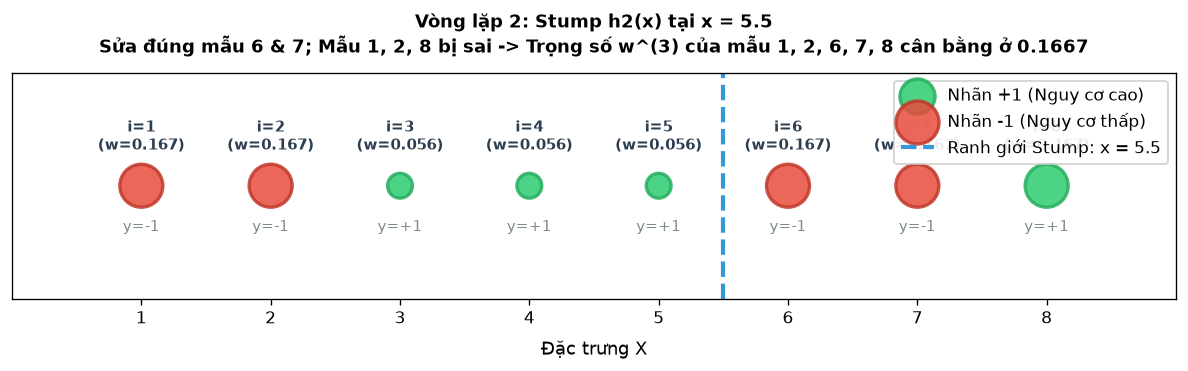

In [5]:
# Stump 2
h2 = np.where(X <= 5.5, 1, -1)
misc2 = (h2 != y)
err2 = np.sum(w2[misc2])
alpha2 = 0.5 * np.log((1 - err2) / err2)
w3_unnorm = w2 * np.exp(-alpha2 * y * h2)
Z2 = np.sum(w3_unnorm)
w3 = w3_unnorm / Z2

print(f"-> Sai số e2: {err2:.4f} (Chính xác = 1/4)")
print(f"-> Trọng số alpha2: {alpha2:.4f} (Chính xác = 0.5 * ln(3))")
print(f"-> Hệ số chuẩn hóa Z2: {Z2:.4f} (Chính xác = sqrt(3)/2)")

plot_samples(X, y, w3, "Vòng lặp 2: Stump h2(x) tại x = 5.5", 
             stump_threshold=5.5, 
             stump_title="Sửa đúng mẫu 6 & 7; Mẫu 1, 2, 8 bị sai -> Trọng số w^(3) của mẫu 1, 2, 6, 7, 8 cân bằng ở 0.1667")

## 4. VÒNG LẶP 3 ($t = 3$)
### 4.1. Chọn mô hình yếu (Decision Stump 3)
Ở vòng này, mẫu 8 có trọng số cao ($0.1667$) và là mẫu nguy cơ cao ($+1$). Stump 3 được chọn:
$$h_3(x) = \begin{cases} +1 & \text{nếu } x > 7.5 \\ -1 & \text{nếu } x \le 7.5 \end{cases}$$

### 4.2. Tính toán các chỉ số:
1. **Kiểm tra sai số:**
   * $X \le 7.5$: Dự đoán $-1$. Đúng cho mẫu 1, 2, 6, 7. Sai cho **mẫu 3, 4, 5**.
   * $X > 7.5$: Dự đoán $+1$. Đúng cho **mẫu 8**.
2. **Sai số phân loại có trọng số $\epsilon_3$:**
   $$\epsilon_3 = w_3^{(3)} + w_4^{(3)} + w_5^{(3)} = \frac{1}{18} + \frac{1}{18} + \frac{1}{18} = \frac{3}{18} = \frac{1}{6} \approx 0.1667$$
3. **Trọng số tin cậy của mô hình $\alpha_3$:**
   $$\alpha_3 = \frac{1}{2} \ln \left( \frac{1 - 1/6}{1/6} \right) = \frac{1}{2} \ln(5) \approx 0.8047$$
   *(Do $\epsilon_3 = 0.1667$ rất nhỏ, Stump 3 có độ tin cậy $\alpha_3$ cao nhất trong 3 mô hình).*

-> Sai số e3: 0.1667 (Chính xác = 1/6)
-> Trọng số alpha3: 0.8047 (Chính xác = 0.5 * ln(5))


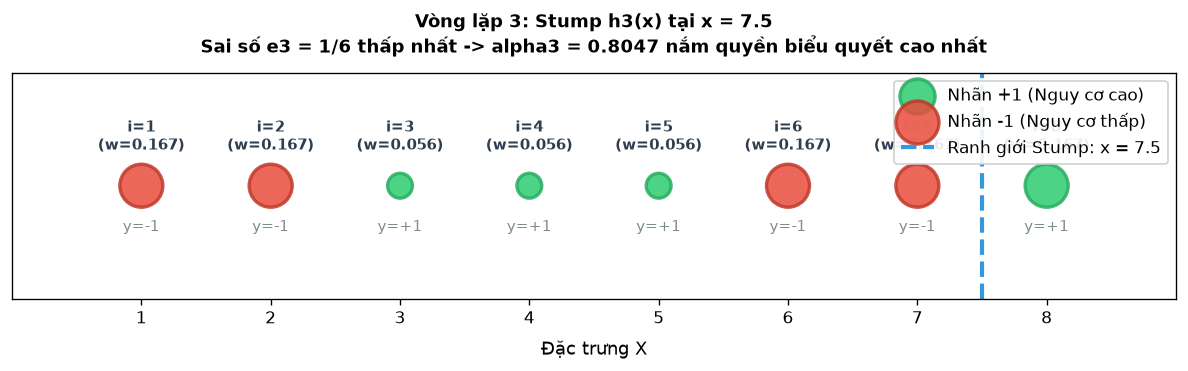

In [6]:
# Stump 3
h3 = np.where(X > 7.5, 1, -1)
misc3 = (h3 != y)
err3 = np.sum(w3[misc3])
alpha3 = 0.5 * np.log((1 - err3) / err3)

print(f"-> Sai số e3: {err3:.4f} (Chính xác = 1/6)")
print(f"-> Trọng số alpha3: {alpha3:.4f} (Chính xác = 0.5 * ln(5))")

plot_samples(X, y, w3, "Vòng lặp 3: Stump h3(x) tại x = 7.5", 
             stump_threshold=7.5, 
             stump_title=f"Sai số e3 = 1/6 thấp nhất -> alpha3 = {alpha3:.4f} nắm quyền biểu quyết cao nhất")

## 5. TỔNG HỢP BIỂU QUYẾT CÓ TRỌNG SỐ (WEIGHTED ENSEMBLE) & KẾT QUẢ

Mô hình Ensemble cuối cùng là tổng kết hợp có trọng số của 3 Decision Stumps:
$$F(x) = \alpha_1 h_1(x) + \alpha_2 h_2(x) + \alpha_3 h_3(x) = 0.5493 \cdot h_1(x) + 0.5493 \cdot h_2(x) + 0.8047 \cdot h_3(x)$$
Dự đoán phân loại nhị phân cuối cùng:
$$H(x) = \text{sign}(F(x))$$

In [7]:
F = alpha1 * h1 + alpha2 * h2 + alpha3 * h3
H = np.sign(F).astype(int)
is_correct = (H == y)

summary_df = pd.DataFrame({
    "Mẫu i": np.arange(1, N + 1),
    "X": X,
    "Nhãn y": y,
    "w^(1)": np.round(w1, 4),
    "h1": h1,
    "w^(2)": np.round(w2, 4),
    "h2": h2,
    "w^(3)": np.round(w3, 4),
    "h3": h3,
    "Score F(x)": np.round(F, 4),
    "Dự đoán H(x)": H,
    "Kết quả": ["ĐÚNG (100%)" if c else "SAI" for c in is_correct]
})
display(summary_df)

accuracy = np.mean(is_correct) * 100
print("=" * 80)
print(f"KẾT QUẢ ĐỐI SOÁT: Độ chính xác đạt {accuracy:.1f}% ({np.sum(is_correct)}/{N} mẫu)")
print(f"Hàm quyết định: H(x) = sign( {alpha1:.4f}*h1(x) + {alpha2:.4f}*h2(x) + {alpha3:.4f}*h3(x) )")
print("=" * 80)

Mẫu i,X,Nhãn y,w^(1),h1,w^(2),h2,w^(3),h3,Score F(x),Dự đoán H(x),Kết quả
1,1,-1,0.125,-1,0.0833,1,0.1667,-1,-0.8047,-1,ĐÚNG (100%)
2,2,-1,0.125,-1,0.0833,1,0.1667,-1,-0.8047,-1,ĐÚNG (100%)
3,3,1,0.125,1,0.0833,1,0.0556,-1,0.2939,1,ĐÚNG (100%)
4,4,1,0.125,1,0.0833,1,0.0556,-1,0.2939,1,ĐÚNG (100%)
5,5,1,0.125,1,0.0833,1,0.0556,-1,0.2939,1,ĐÚNG (100%)
6,6,-1,0.125,1,0.2500,-1,0.1667,-1,-0.8047,-1,ĐÚNG (100%)
7,7,-1,0.125,1,0.2500,-1,0.1667,-1,-0.8047,-1,ĐÚNG (100%)
8,8,1,0.125,1,0.0833,-1,0.1667,1,0.8047,1,ĐÚNG (100%)


KẾT QUẢ ĐỐI SOÁT: Độ chính xác đạt 100.0% (8/8 mẫu)
Hàm quyết định: H(x) = sign( 0.5493*h1(x) + 0.5493*h2(x) + 0.8047*h3(x) )


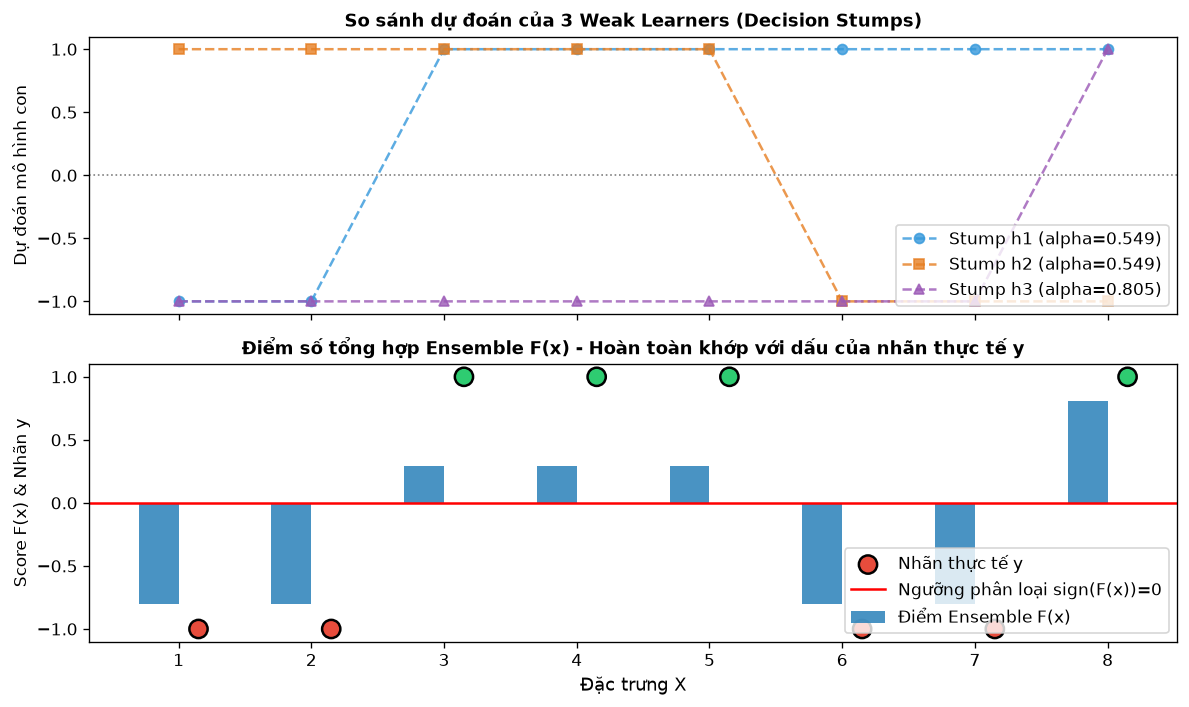

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Đồ thị 1: Các Decision Stumps thành phần
ax1.plot(X, h1, "o--", color="#3498db", label=f"Stump h1 (alpha={alpha1:.3f})", alpha=0.8)
ax1.plot(X, h2, "s--", color="#e67e22", label=f"Stump h2 (alpha={alpha2:.3f})", alpha=0.8)
ax1.plot(X, h3, "^--", color="#9b59b6", label=f"Stump h3 (alpha={alpha3:.3f})", alpha=0.8)
ax1.axhline(0, color="gray", linestyle=":", linewidth=1)
ax1.set_ylabel("Dự đoán mô hình con", fontsize=10)
ax1.set_title("So sánh dự đoán của 3 Weak Learners (Decision Stumps)", fontsize=11, fontweight="bold")
ax1.legend(loc="lower right")

# Đồ thị 2: Điểm kết hợp Ensemble F(x) và nhãn thật y
ax2.bar(X - 0.15, F, width=0.3, color="#2980b9", label="Điểm Ensemble F(x)", alpha=0.85)
ax2.scatter(X + 0.15, y, color=["#2ecc71" if val==1 else "#e74c3c" for val in y], 
            s=120, edgecolors="black", linewidth=1.5, label="Nhãn thực tế y", zorder=3)
ax2.axhline(0, color="red", linestyle="-", linewidth=1.5, label="Ngưỡng phân loại sign(F(x))=0")
ax2.set_xlabel("Đặc trưng X", fontsize=11)
ax2.set_ylabel("Score F(x) & Nhãn y", fontsize=10)
ax2.set_title("Điểm số tổng hợp Ensemble F(x) - Hoàn toàn khớp với dấu của nhãn thực tế y", fontsize=11, fontweight="bold")
ax2.set_xticks(range(1, 9))
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()